# Day 1, step 2: forecast the temperature 1 hour ahead 

## 1. Setup

In [1]:
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from pathlib import Path
from sklearn.ensemble import HistGradientBoostingRegressor

DATA_PATH = "../data/mumbai_clean.csv"
MODEL_PATH = Path("../models/gb_simple_h1.joblib")
AREA = "South_Mumbai"
RANDOM_STATE = 42

## 2. Load the clean data

In [2]:
if not Path(DATA_PATH).exists():
    raise FileNotFoundError(f"{DATA_PATH} not found. Run day1_data_exploration.ipynb first.")

df = pd.read_csv(DATA_PATH, parse_dates=["time"], index_col="time")

print(f"{len(df):,} hours, from {df.index.min()} to {df.index.max()}")
df.head()

403,248 hours, from 1980-01-01 00:00:00 to 2025-12-31 23:00:00


,temperature_2m,precipitation,shortwave_radiation
time,,,
1980-01-01 00:00:00,22.3,0.0,0.0
1980-01-01 01:00:00,22.0,0.0,0.0
1980-01-01 02:00:00,20.9,0.0,0.0
1980-01-01 03:00:00,20.4,0.0,0.0
1980-01-01 04:00:00,20.3,0.0,0.0


## 3. Make the 6 features

In [3]:
data = pd.DataFrame(index=df.index)
data["temp_now"] = df["temperature_2m"]
data["temp_3h_ago"] = df["temperature_2m"].shift(3)
data["temp_avg_24h"] = df["temperature_2m"].rolling(24).mean()
data["sunlight"] = df["shortwave_radiation"]
data["rain"] = df["precipitation"]
data["hour"] = df.index.hour

data["temp_next_hour"] = df["temperature_2m"].shift(-1)

data = data.dropna()

FEATURES = ["temp_now", "temp_3h_ago", "temp_avg_24h", "sunlight", "rain", "hour"]
TARGET = "temp_next_hour"
data.head()

,temp_now,temp_3h_ago,temp_avg_24h,sunlight,rain,hour,temp_next_hour
time,,,,,,,
1980-01-01 23:00:00,22.3,22.9,23.041667,0.0,0.0,23,22.0
1980-01-02 00:00:00,22.0,24.2,23.029167,0.0,0.0,0,21.5
1980-01-02 01:00:00,21.5,23.4,23.008333,0.0,0.0,1,21.1
1980-01-02 02:00:00,21.1,22.3,23.016667,0.0,0.0,2,21.3
1980-01-02 03:00:00,21.3,22.0,23.054167,0.0,0.0,3,21.5


## 4. Split by time

In [4]:
train = data[data.index < "2022-01-01"]
val = data[(data.index >= "2022-01-01") & (data.index < "2024-01-01")]
test = data[data.index >= "2024-01-01"]

print(f"train {len(train):,} rows | validation {len(val):,} rows | test {len(test):,} rows")

train 368,161 rows | validation 17,520 rows | test 17,543 rows


## 5. The lazy guess (baseline)

In [5]:
def rmse(actual, predicted):
    return float(np.sqrt(np.mean((np.asarray(actual) - np.asarray(predicted)) ** 2)))

print(f"Lazy guess, validation RMSE: {rmse(val[TARGET], val['temp_now']):.4f} C")

Lazy guess, validation RMSE: 0.8529 C


## 6. Train gradient boosting

In [6]:
model = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.1, random_state=RANDOM_STATE)
model.fit(train[FEATURES], train[TARGET])

val_model = rmse(val[TARGET], model.predict(val[FEATURES]))
val_lazy = rmse(val[TARGET], val["temp_now"])
print(f"Validation RMSE: model {val_model:.4f} C vs lazy guess {val_lazy:.4f} C")
print(f"The model is {100 * (1 - val_model / val_lazy):.1f}% better")

Validation RMSE: model 0.3980 C vs lazy guess 0.8529 C
The model is 53.3% better


## 7. Final model + test

In [7]:
train_val = pd.concat([train, val])
final_model = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.1, random_state=RANDOM_STATE)
final_model.fit(train_val[FEATURES], train_val[TARGET])

test_pred = final_model.predict(test[FEATURES])
test_model = rmse(test[TARGET], test_pred)
test_lazy = rmse(test[TARGET], test["temp_now"])
gain = 100 * (1 - test_model / test_lazy)

print(f"TEST (2024-2025): model {test_model:.4f} C vs lazy guess {test_lazy:.4f} C")
print(f"The model is {gain:.1f}% better  ->  F1 {'PASSED' if gain > 0 else 'FAILED'}")

TEST (2024-2025): model 0.4116 C vs lazy guess 0.8502 C
The model is 51.6% better  ->  F1 PASSED


## 8. Look at the predictions

In [8]:
results = pd.DataFrame({
    "temp_now": test["temp_now"],
    "actual_next_hour": test[TARGET],
    "predicted_next_hour": test_pred.round(2),
})
results["error"] = (results["predicted_next_hour"] - results["actual_next_hour"]).round(2)
results.head(12)

,temp_now,actual_next_hour,predicted_next_hour,error
time,,,,
2024-01-01 00:00:00,24.3,23.5,23.65,0.15
2024-01-01 01:00:00,23.5,23.6,23.09,-0.51
2024-01-01 02:00:00,23.6,22.5,22.93,0.43
2024-01-01 03:00:00,22.5,21.9,22.23,0.33
2024-01-01 04:00:00,21.9,21.9,21.89,-0.01
2024-01-01 05:00:00,21.9,22.3,21.80,-0.50
2024-01-01 06:00:00,22.3,22.1,23.00,0.90
2024-01-01 07:00:00,22.1,22.2,22.70,0.50
2024-01-01 08:00:00,22.2,23.2,23.71,0.51


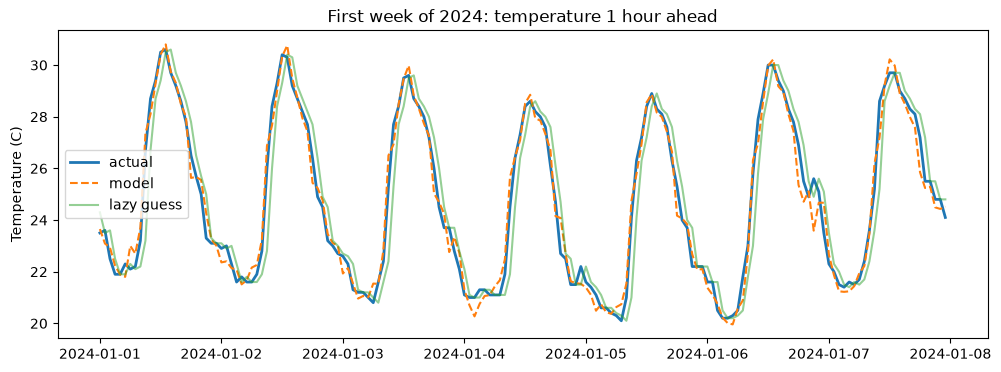

In [9]:
week = results.iloc[: 24 * 7]
plt.figure(figsize=(12, 4))
plt.plot(week.index, week["actual_next_hour"], label="actual", linewidth=2)
plt.plot(week.index, week["predicted_next_hour"], "--", label="model")
plt.plot(week.index, week["temp_now"], alpha=0.5, label="lazy guess")
plt.title("First week of 2024: temperature 1 hour ahead")
plt.ylabel("Temperature (C)")
plt.legend()
plt.show()

## 9. Save the model

In [10]:
MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)
joblib.dump({
    "model": final_model,
    "features": FEATURES,
    "area": AREA,
    "test_rmse": test_model,
    "sklearn_version": sklearn.__version__,
}, MODEL_PATH)
print(f"Saved to {MODEL_PATH}")

Saved to ..\models\gb_simple_h1.joblib


## 10. `predict_next_hour()`, for the Day 3 agent

In [11]:
def predict_next_hour(last_24h, saved):
    needed = ["temperature_2m", "shortwave_radiation", "precipitation"]
    if len(last_24h) != 24:
        raise ValueError(f"Need exactly 24 hourly rows, got {len(last_24h)}")
    if not (last_24h.index.to_series().diff().dropna() == pd.Timedelta(hours=1)).all():
        raise ValueError("Rows must be 24 consecutive hours")
    if last_24h[needed].isna().any().any():
        raise ValueError("Input has missing values")

    now = last_24h.index[-1]
    temp = last_24h["temperature_2m"]
    row = pd.DataFrame([{
        "temp_now": temp.iloc[-1],
        "temp_3h_ago": temp.iloc[-4],
        "temp_avg_24h": temp.mean(),
        "sunlight": last_24h["shortwave_radiation"].iloc[-1],
        "rain": last_24h["precipitation"].iloc[-1],
        "hour": now.hour,
    }])[saved["features"]]

    return {
        "time_now": now,
        "forecast_time": now + pd.Timedelta(hours=1),
        "forecast_temp_c": round(float(saved["model"].predict(row)[0]), 2),
    }

In [12]:
saved = joblib.load(MODEL_PATH)

now = pd.Timestamp("2024-05-10 14:00")
last_24h = df.loc[now - pd.Timedelta(hours=23): now]

forecast = predict_next_hour(last_24h, saved)
actual = df.loc[forecast["forecast_time"], "temperature_2m"]
print(f"Forecast for {forecast['forecast_time']}: {forecast['forecast_temp_c']} C (actual {actual} C)")

assert abs(forecast["forecast_temp_c"] - results.loc[now, "predicted_next_hour"]) < 0.01
print("Check passed: same answer as the test predictions")

try:
    predict_next_hour(last_24h.iloc[:10], saved)
except ValueError as error:
    print("Bad input rejected:", error)

Forecast for 2024-05-10 15:00:00: 31.56 C (actual 31.6 C)
Check passed: same answer as the test predictions
Bad input rejected: Need exactly 24 hourly rows, got 10
